# CIMD-GeoFM v3 — DFC2020 (Sentinel-1/2) + pretrained ResNet-50 dual-stream

**What is new compared with v2**
1. **Second dataset: DFC2020** (IEEE GRSS Data Fusion Contest 2020, built on SEN12MS): Sentinel-2 (13 bands) + Sentinel-1 (VV, VH), 10 m, 256×256 patches with high-resolution semi-manual labels.
2. **Geographically disjoint split**: patches are grouped into regions from their GeoTIFF coordinates, and whole regions go to train / val / test, so the test regions are geographically unseen.
3. **Pretrained CNN backbone**: dual-stream ResNet-50. For DFC2020 the default is **SSL4EO-S12 self-supervised Sentinel-1 / Sentinel-2 weights** (TorchGeo). ImageNet ResNet-50 / ResNeXt-50 and a no-pretraining control are switchable in Cell 1.
4. **BatchNorm is frozen** in pretrained encoders (fixed statistics) so the zeroed-modality passes cannot corrupt them; the decoder uses GroupNorm.
5. **A0F** (fair full-modality baseline, selected on FULL accuracy, no early stop), failure forecast with class-prior baselines, and paper packaging are built in.

The same notebook also runs on **WHU-OPT-SAR** (`DATASET = "WHU"`), so both datasets use one code path.

**Run order:** Cells 1–5 every session → training Cells 7–9 (resume-safe) → results Cells 10–14.

**Install once (in this environment):** `%pip install timm torchgeo`

In [1]:
%pip install timm torchgeo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys; print(sys.executable)

F:\JShanthini\anaconda3\envs\mot\python.exe


In [4]:
import sys
print("Python:", sys.executable)
sys.path = [p for p in sys.path if "AppData\\Roaming\\Python" not in p]
import rasterio, timm, torchgeo
print("rasterio", rasterio.__version__, "| timm", timm.__version__, "| torchgeo", torchgeo.__version__)

Python: F:\JShanthini\anaconda3\envs\mot\python.exe
rasterio 1.4.4 | timm 1.0.30 | torchgeo 0.8.1


In [1]:
# ============================================================
# CELL 1 — IMPORTS, CONFIGURATION, PATHS
# ============================================================
import os, re, sys, json, time, random, string, shutil, warnings
from pathlib import Path
from collections import defaultdict
from functools import partial

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm as _tqdm
import matplotlib.pyplot as plt
from IPython.display import display
import rasterio
from rasterio.errors import NotGeoreferencedWarning
from rasterio.warp import transform as warp_transform
import timm

warnings.filterwarnings("ignore", category=NotGeoreferencedWarning)
tqdm = partial(_tqdm, mininterval=10)          # avoids "IOPub message rate exceeded"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| timm:", timm.__version__, "| Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ---------------- main switches ----------------
DATASET = "DFC2020"                # "DFC2020" or "WHU"
BACKBONE = "ssl4eo_resnet50"       # "ssl4eo_resnet50"   (Sentinel-pretrained; DFC2020 only)
                                   # "imagenet_resnet50" | "imagenet_resnext50" | "random_resnet50"
LOAD_PRETRAINED = True             # leave True (False only for offline testing)
SPLIT_MODE = "official"            # DFC2020: "official" (separate releases), "region" (needs real coordinates) or "random"
SPLIT_FRACTIONS = (0.60, 0.15, 0.25)
REGION_LINK_KM = 50                # patches closer than this belong to the same region

#DFC_DIR_OVERRIDE = None            # e.g. r"D:\DFC2020"  (folder holding ROIs0000_validation / ROIs0000_test)
DFC_DIR_OVERRIDE = r"F:\JShanthini\content\DFC2020"
WHU_DIR_OVERRIDE = None            # e.g. r"C:\content\WHU_OPT_SAR_EXTRACTED"

if BACKBONE.startswith("ssl4eo") and DATASET != "DFC2020":
    raise ValueError("SSL4EO weights are Sentinel-specific. For WHU use imagenet_resnet50 / imagenet_resnext50.")

# ---------------- training ----------------
SEEDS = [42, 43, 44]               # paper setting
PATCH_SIZE = 256
BATCH_SIZE = 8                     # paper setting (24 GB GPU); use 4 or 2 if "CUDA out of memory"
EVAL_BATCH_SIZE = 16
EPOCHS = 25                        # paper setting; keep fixed while a run is half-finished
PATIENCE = 5
LR = 3e-4                          # decoder / heads
ENCODER_LR_MULT = 0.1              # pretrained encoders learn 10x slower
WEIGHT_DECAY = 1e-4
USE_AMP = (DEVICE == "cuda")
# bfloat16 has the fp32 range -> no fp16 overflow / NaN losses (Ada, Ampere and newer GPUs)
AMP_DTYPE = torch.bfloat16 if (DEVICE == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
USE_CLASS_WEIGHTS = True
GN_GROUPS = 8
DEC_CH = 128
IGNORE_INDEX = 255

# Partial sensor-gap augmentation: with this probability a training batch has a random
# 25/50/75 % of 32x32 blocks blanked in one modality (applied identically to every experiment).
# 0.0 reproduces the v2 protocol (whole-modality removal only). See Cell 12: without it,
# partially gapped inputs score LOWER than fully missing ones.
PARTIAL_GAP_PROB = 0.0

# CIMD coefficients (unchanged)
ALPHA, BETA, GAMMA, DELTA, TAU = 0.50, 0.20, 0.30, 0.10, 0.05

EXPERIMENTS = {
    "A0F": "Full-modality baseline (selected on FULL accuracy)",
    "A1": "Missing-modality supervised training",
    "A2": "Uniform consistency",
    "A3": "CIMD dependency estimator + DWCR",
}

# ---------------- dataset definitions ----------------
if DATASET == "WHU":
    CLASS_NAMES = ["farmland", "city", "village", "water", "forest", "road", "others"]
    RAW_TO_CLASS = {10: 0, 20: 1, 30: 2, 40: 3, 50: 4, 60: 5, 70: 6}
else:
    # DFC2020 simplified IGBP: 1 forest, 2 shrubland, 3 savanna, 4 grassland, 5 wetland,
    # 6 cropland, 7 urban, 8 snow/ice, 9 barren, 10 water. Savanna and snow/ice are
    # ignored, as in the DFC2020 evaluation protocol (8 classes remain).
    CLASS_NAMES = ["forest", "shrubland", "grassland", "wetland", "cropland", "urban", "barren", "water"]
    RAW_TO_CLASS = {1: 0, 2: 1, 4: 2, 5: 3, 6: 4, 7: 5, 9: 6, 10: 7}
NUM_CLASSES = len(CLASS_NAMES)

# Sentinel encodings used for the uint8 cache (decoded back exactly in Cell 4)
S2_MAX = 5000.0                    # S2 reflectance (x10000) clipped to 0..5000
S1_MIN_DB, S1_MAX_DB = -40.0, 10.0
SSL4EO_S1_MEAN, SSL4EO_S1_STD = [-12.59, -20.26], [5.26, 5.91]   # TorchGeo SSL4EO-S12 S1 normalisation

# ---------------- paths ----------------
def find_folder(rel, must_contain):
    cands = [Path("/" + rel)] + [Path(f"{d}:/{rel}") for d in string.ascii_uppercase]
    for c in cands:
        try:
            if c.exists() and any(c.rglob(must_contain)):
                return c
        except OSError:
            pass
    return None

if DATASET == "WHU":
    DATA_DIR = Path(WHU_DIR_OVERRIDE) if WHU_DIR_OVERRIDE else find_folder("content/WHU_OPT_SAR_EXTRACTED", "*.tif")
else:
    DATA_DIR = Path(DFC_DIR_OVERRIDE) if DFC_DIR_OVERRIDE else find_folder("content/DFC2020", "*.tif")
if DATA_DIR is None or not DATA_DIR.exists():
    raise RuntimeError(f"{DATASET} data folder not found. Set {'WHU' if DATASET == 'WHU' else 'DFC'}_DIR_OVERRIDE.")

ROOT = DATA_DIR.parent
OUT_DIR = ROOT / f"CIMD_v3_{DATASET}_{BACKBONE}" if PARTIAL_GAP_PROB == 0 else ROOT / f"CIMD_v3_{DATASET}_{BACKBONE}_gap{PARTIAL_GAP_PROB:g}"
CKPT_DIR = OUT_DIR / "checkpoints"
CACHE_DIR = ROOT / f"{DATASET}_CACHE_{PATCH_SIZE}_v3"
for p in [OUT_DIR, CKPT_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)
print("Data   :", DATA_DIR.resolve())
print("Results:", OUT_DIR.resolve())
print("Cache  :", CACHE_DIR.resolve())

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(42)

PyTorch: 2.6.0+cu124 | timm: 1.0.30 | Device: cuda
GPU: NVIDIA RTX 4500 Ada Generation | 25.8 GB
Data   : F:\JShanthini\content\DFC2020
Results: F:\JShanthini\content\CIMD_v3_DFC2020_ssl4eo_resnet50
Cache  : F:\JShanthini\content\DFC2020_CACHE_256_v3


In [2]:
# ============================================================
# CELL 2 — FIND FILES + SPLIT (WHU: scene split | DFC2020: region split)
# ============================================================
if DATASET == "WHU":
    groups = defaultdict(list)
    for p in sorted(DATA_DIR.rglob("*.tif")):
        groups[p.parent.name.lower()].append(p)
    FILES = {"opt": {p.stem: p for p in groups["optical"]},
             "sar": {p.stem: p for p in groups["sar"]},
             "lbl": {p.stem: p for p in groups["lbl"]}}
    ids = sorted(set(FILES["opt"]) & set(FILES["sar"]) & set(FILES["lbl"]))
    print("Matched WHU scenes:", len(ids))
    old = [ROOT / "CIMD_GeoFM_WHU_RESULTS_GN" / "scene_split.csv", ROOT / "CIMD_GeoFM_WHU_RESULTS" / "scene_split.csv"]
    old = [p for p in old if p.exists()]
    if old:
        split_df = pd.read_csv(old[0]); split_df["scene"] = split_df["scene"].astype(str)
        print("Reusing the earlier WHU split:", old[0])
    else:
        arr = np.array(ids); np.random.default_rng(42).shuffle(arr)
        n = len(arr); n_te = int(round(0.2 * n)); n_va = int(round(0.16 * n)); n_tr = n - n_va - n_te
        split_df = pd.DataFrame([{"scene": s, "split": "train"} for s in arr[:n_tr]] +
                                [{"scene": s, "split": "val"} for s in arr[n_tr:n_tr + n_va]] +
                                [{"scene": s, "split": "test"} for s in arr[n_tr + n_va:]])
    split_df["region"] = -1
else:
    MOD = {"s2": "opt", "s1": "sar", "dfc": "lbl"}          # "lc" (MODIS 500 m) is ignored
    tok = re.compile(r"_(s1|s2|dfc|lc)_", re.IGNORECASE)
    FILES = {"opt": {}, "sar": {}, "lbl": {}}
    for p in sorted(DATA_DIR.rglob("*.tif")):
        if "__MACOSX" in p.parts or p.name.startswith("._"):
            continue                                          # Mac metadata, not images
        folder = p.parent.name.lower().split("_")[0]          # s1_validation -> s1, dfc_0 -> dfc
        m = folder if folder in MOD or folder == "lc" else None
        if m is None:
            mt = tok.search(p.stem)
            m = mt.group(1).lower() if mt else None
        if m not in MOD:
            continue
        key = tok.sub("_X_", p.stem)
        FILES[MOD[m]][key] = p
    ids = sorted(set(FILES["opt"]) & set(FILES["sar"]) & set(FILES["lbl"]))
    print("S2 / S1 / DFC label files:", len(FILES["opt"]), len(FILES["sar"]), len(FILES["lbl"]))
    print("Matched DFC2020 triplets:", len(ids))
    if not ids:
        raise RuntimeError("No S1/S2/DFC triplets matched. Send the output of os.listdir() on the DFC2020 folder.")

    # ---- geolocate every patch from its GeoTIFF ----
    lon, lat, georef = np.zeros(len(ids)), np.zeros(len(ids)), True
    for i, k in enumerate(tqdm(ids if SPLIT_MODE == "region" else [], desc="Reading patch locations")):
        with rasterio.open(FILES["opt"][k]) as src:
            if src.crs is None:
                georef = False; break
            b = src.bounds
            xs, ys = warp_transform(src.crs, "EPSG:4326", [(b.left + b.right) / 2], [(b.bottom + b.top) / 2])
            lon[i], lat[i] = xs[0], ys[0]

    if SPLIT_MODE == "official":
        # DFC2020 hides patch locations, so regions cannot be recovered from the files.
        # Use the two officially separate releases: "validation" (986) -> TEST,
        # "test" (~5128) -> TRAIN + VAL (15 % held out for model selection).
        is_test = np.array(["_validation_" in k.lower() for k in ids])
        pool = np.random.default_rng(42).permutation(np.flatnonzero(~is_test))
        n_va = int(0.15 * len(pool))
        sp = np.empty(len(ids), dtype=object)
        sp[is_test] = "test"; sp[pool[:n_va]] = "val"; sp[pool[n_va:]] = "train"
        split_df = pd.DataFrame({"scene": ids, "region": -1, "split": sp, "lat": lat, "lon": lon})
        print("Official split: DFC2020 'validation' release = TEST; 'test' release = TRAIN/VAL")
    elif SPLIT_MODE == "region" and georef:
        # union patches closer than REGION_LINK_KM (great-circle chord distance on the unit sphere)
        la, lo = np.radians(lat), np.radians(lon)
        xyz = np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], 1)
        thr = 2 * np.sin(REGION_LINK_KM / 6371.0 / 2)
        parent = np.arange(len(ids))
        def find(a):
            while parent[a] != a:
                parent[a] = parent[parent[a]]; a = parent[a]
            return a
        for s0 in range(0, len(ids), 1000):
            d = np.linalg.norm(xyz[s0:s0 + 1000, None, :] - xyz[None, :, :], axis=2)
            for i, j in zip(*np.nonzero(d < thr)):
                ri, rj = find(s0 + i), find(j)
                if ri != rj:
                    parent[ri] = rj
        roots = np.array([find(i) for i in range(len(ids))])
        _, region = np.unique(roots, return_inverse=True)

        reg = (pd.DataFrame({"region": region, "lat": lat, "lon": lon})
               .groupby("region").agg(n=("lat", "size"), lat=("lat", "mean"), lon=("lon", "mean"))
               .sort_values("n", ascending=False))
        if len(reg) < 3:
            raise RuntimeError(f"Only {len(reg)} regions found; lower REGION_LINK_KM or use SPLIT_MODE='random'.")
        targets = {sp: f * len(ids) for sp, f in zip(["train", "val", "test"], SPLIT_FRACTIONS)}
        counts = {"train": 0, "val": 0, "test": 0}
        assign = {}
        for rank, (r, row) in enumerate(reg.iterrows()):
            if rank < 3:                                   # guarantee every split gets a region
                sp = ["train", "test", "val"][rank]
            else:
                sp = max(counts, key=lambda k: (targets[k] - counts[k]) / targets[k])
            assign[r] = sp; counts[sp] += row["n"]
        reg["split"] = [assign[r] for r in reg.index]
        reg.to_csv(OUT_DIR / "dfc2020_regions.csv")
        print("\nRegions (whole regions go to one split -> test regions are geographically unseen):")
        display(reg.round(2))
        split_df = pd.DataFrame({"scene": ids, "region": region,
                                 "split": [assign[r] for r in region], "lat": lat, "lon": lon})
    else:
        if SPLIT_MODE == "region":
            print("WARNING: files carry no coordinates -> falling back to a random split.")
        perm = np.random.default_rng(42).permutation(len(ids))
        n_tr = int(SPLIT_FRACTIONS[0] * len(ids)); n_va = int(SPLIT_FRACTIONS[1] * len(ids))
        sp = np.empty(len(ids), dtype=object)
        sp[perm[:n_tr]] = "train"; sp[perm[n_tr:n_tr + n_va]] = "val"; sp[perm[n_tr + n_va:]] = "test"
        split_df = pd.DataFrame({"scene": ids, "region": -1, "split": sp, "lat": lon * 0, "lon": lon * 0})

split_df.to_csv(OUT_DIR / "split.csv", index=False)
SPLIT = {k: split_df.loc[split_df["split"] == k, "scene"].astype(str).tolist() for k in ["train", "val", "test"]}
print({k: len(v) for k, v in SPLIT.items()})

S2 / S1 / DFC label files: 6114 6114 6114
Matched DFC2020 triplets: 6114


Reading patch locations: 0it [00:00, ?it/s]

Official split: DFC2020 'validation' release = TEST; 'test' release = TRAIN/VAL
{'train': 4359, 'val': 769, 'test': 986}


In [3]:
# ============================================================
# CELL 3 — ONE-TIME PATCH CACHE (uint8 .npy, memory-mapped)
# ============================================================
LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for raw, cls in RAW_TO_CLASS.items():
    LABEL_LUT[raw] = cls

def convert_label(y):
    y = np.nan_to_num(y.astype(np.float64), nan=0).astype(np.int64)
    out = np.full(y.shape, IGNORE_INDEX, dtype=np.uint8)
    ok = (y >= 0) & (y < 256)
    out[ok] = LABEL_LUT[y[ok]]
    return out

def enc_minmax_uint8(arr):                       # WHU: per-scene 2–98 % stretch
    arr = arr.astype(np.float32); out = np.zeros(arr.shape, np.uint8)
    for c in range(arr.shape[0]):
        sub = arr[c, ::4, ::4]; sub = sub[np.isfinite(sub)]
        if sub.size:
            lo, hi = np.percentile(sub, [2, 98])
            if hi > lo:
                out[c] = np.round(np.clip((np.nan_to_num(arr[c], nan=lo) - lo) / (hi - lo), 0, 1) * 255)
    return out

def enc_s2(x):
    return np.round(np.clip(np.nan_to_num(x.astype(np.float32)), 0, S2_MAX) / S2_MAX * 255).astype(np.uint8)

def enc_s1(x):
    x = np.nan_to_num(x.astype(np.float32), nan=S1_MIN_DB, neginf=S1_MIN_DB, posinf=S1_MAX_DB)
    return np.round((np.clip(x, S1_MIN_DB, S1_MAX_DB) - S1_MIN_DB) / (S1_MAX_DB - S1_MIN_DB) * 255).astype(np.uint8)

def center_crop(a, size):
    H, W = a.shape[-2:]
    if H < size or W < size:
        raise RuntimeError(f"Patch {H}x{W} is smaller than {size}")
    r, c = (H - size) // 2, (W - size) // 2
    return a[..., r:r + size, c:c + size]

def cache_paths(split):
    return {k: CACHE_DIR / f"{split}_{k}.npy" for k in ["opt", "sar", "lbl"]}, CACHE_DIR / f"{split}_meta.json"

def build_cache(split):
    paths, meta_path = cache_paths(split)
    cfg = {"dataset": DATASET, "patch": PATCH_SIZE, "ids": SPLIT[split], "s2max": S2_MAX,
           "s1": [S1_MIN_DB, S1_MAX_DB], "lut": sorted(RAW_TO_CLASS.items())}
    if meta_path.exists() and all(p.exists() for p in paths.values()) and json.loads(meta_path.read_text()) == json.loads(json.dumps(cfg)):
        d = {k: np.load(p, mmap_mode="r") for k, p in paths.items()}
        print(f"{split:5s}: loaded {len(d['lbl'])} cached patches")
        return d

    if DATASET == "DFC2020":
        n = len(SPLIT[split])
        with rasterio.open(FILES["opt"][SPLIT[split][0]]) as s: co = s.count
        with rasterio.open(FILES["sar"][SPLIT[split][0]]) as s: cs = s.count
        mm = {"opt": np.lib.format.open_memmap(paths["opt"], "w+", np.uint8, (n, co, PATCH_SIZE, PATCH_SIZE)),
              "sar": np.lib.format.open_memmap(paths["sar"], "w+", np.uint8, (n, cs, PATCH_SIZE, PATCH_SIZE)),
              "lbl": np.lib.format.open_memmap(paths["lbl"], "w+", np.uint8, (n, PATCH_SIZE, PATCH_SIZE))}
        for i, k in enumerate(tqdm(SPLIT[split], desc=f"Caching {split}")):
            with rasterio.open(FILES["opt"][k]) as s: mm["opt"][i] = enc_s2(center_crop(s.read(), PATCH_SIZE))
            with rasterio.open(FILES["sar"][k]) as s: mm["sar"][i] = enc_s1(center_crop(s.read(), PATCH_SIZE))
            with rasterio.open(FILES["lbl"][k]) as s: mm["lbl"][i] = convert_label(center_crop(s.read(1), PATCH_SIZE))
        for a in mm.values():
            a.flush()
        del mm
    else:                                            # WHU: crops from large scenes (as in v2)
        rng = np.random.default_rng(1234 + ["train", "val", "test"].index(split))
        O, S, Y = [], [], []
        for sid in tqdm(SPLIT[split], desc=f"Caching {split}"):
            with rasterio.open(FILES["opt"][sid]) as s: o = enc_minmax_uint8(s.read())
            with rasterio.open(FILES["sar"][sid]) as s: r = enc_minmax_uint8(s.read())
            with rasterio.open(FILES["lbl"][sid]) as s: y = convert_label(s.read(1))
            H, W = y.shape
            if split == "train":
                pos = []
                for _ in range(24):
                    for _ in range(30):
                        rr, cc = int(rng.integers(0, H - PATCH_SIZE + 1)), int(rng.integers(0, W - PATCH_SIZE + 1))
                        if np.mean(y[rr:rr + PATCH_SIZE, cc:cc + PATCH_SIZE] != IGNORE_INDEX) >= 0.05:
                            break
                    pos.append((rr, cc))
            else:
                st = 768 if split == "val" else 512
                pos = [(rr, cc) for rr in range(0, H - PATCH_SIZE + 1, st) for cc in range(0, W - PATCH_SIZE + 1, st)
                       if np.mean(y[rr:rr + PATCH_SIZE, cc:cc + PATCH_SIZE] != IGNORE_INDEX) >= 0.05]
            for rr, cc in pos:
                O.append(o[:, rr:rr + PATCH_SIZE, cc:cc + PATCH_SIZE]); S.append(r[:, rr:rr + PATCH_SIZE, cc:cc + PATCH_SIZE])
                Y.append(y[rr:rr + PATCH_SIZE, cc:cc + PATCH_SIZE])
        for k, arr in [("opt", np.stack(O)), ("sar", np.stack(S)), ("lbl", np.stack(Y))]:
            np.save(paths[k], arr)
    meta_path.write_text(json.dumps(cfg))
    d = {k: np.load(p, mmap_mode="r") for k, p in paths.items()}
    print(f"{split:5s}: built {len(d['lbl'])} patches")
    return d

CACHE = {sp: build_cache(sp) for sp in ["train", "val", "test"]}
OPT_CH, SAR_CH = CACHE["train"]["opt"].shape[1], CACHE["train"]["sar"].shape[1]
print("Optical channels:", OPT_CH, "| SAR channels:", SAR_CH)

# class frequencies (train only, chunked) -> CE weights
counts = np.zeros(256, np.int64)
for s0 in range(0, len(CACHE["train"]["lbl"]), 256):
    counts += np.bincount(np.asarray(CACHE["train"]["lbl"][s0:s0 + 256]).ravel(), minlength=256)
freq = counts[:NUM_CLASSES] / max(counts[:NUM_CLASSES].sum(), 1)
w = 1.0 / np.sqrt(freq + 1e-6); w = np.clip(w / w.mean(), 0.5, 5.0)
CLASS_WEIGHTS = torch.tensor(w, dtype=torch.float32)
print(f"Ignored pixels in train: {100 * counts[IGNORE_INDEX] / counts.sum():.1f} %")
display(pd.DataFrame({"class": CLASS_NAMES, "train_pixel_share_%": (100 * freq).round(2), "CE_weight": w.round(3)}))

train: loaded 4359 cached patches
val  : loaded 769 cached patches
test : loaded 986 cached patches
Optical channels: 13 | SAR channels: 2
Ignored pixels in train: 0.0 %


,class,train_pixel_share_%,CE_weight
0,forest,25.48,0.534
1,shrubland,5.89,1.112
2,grassland,10.30,0.840
3,wetland,2.07,1.876
4,cropland,19.83,0.606
5,urban,10.85,0.819
6,barren,2.68,1.649
7,water,22.90,0.564


In [4]:
# ============================================================
# CELL 4 — DATASETS, INPUT NORMALISATION, LOADERS
# ============================================================
SSL4EO = BACKBONE.startswith("ssl4eo")
_s1m = torch.tensor(SSL4EO_S1_MEAN).view(-1, 1, 1); _s1s = torch.tensor(SSL4EO_S1_STD).view(-1, 1, 1)

def decode(q, kind):
    """uint8 cache -> physical units (S2 reflectance/10000, S1 dB) or [0,1] for WHU."""
    q = q.float()
    if DATASET == "WHU":
        return q / 255.0
    if kind == "opt":
        return q * (S2_MAX / 255.0 / 10000.0)
    return q * ((S1_MAX_DB - S1_MIN_DB) / 255.0) + S1_MIN_DB

# Per-channel standardisation for ImageNet / random backbones (estimated on training patches).
# SSL4EO keeps the exact normalisation its weights were trained with.
idx = np.random.default_rng(0).choice(len(CACHE["train"]["lbl"]), size=min(300, len(CACHE["train"]["lbl"])), replace=False)
NORM = {}
for kind in ["opt", "sar"]:
    x = decode(torch.from_numpy(np.asarray(CACHE["train"][kind][np.sort(idx)])), kind)
    NORM[kind] = (x.mean((0, 2, 3)).view(-1, 1, 1), x.std((0, 2, 3)).clamp_min(1e-3).view(-1, 1, 1))

def normalise(x, kind):
    if SSL4EO:
        return x if kind == "opt" else (x - _s1m) / _s1s       # S2: /10000 (already) | S1: dB standardised
    m, s = NORM[kind]
    return (x - m) / s

class CachedPatches(Dataset):
    def __init__(self, d, augment=False):
        self.o, self.s, self.y = d["opt"], d["sar"], d["lbl"]
        self.augment = augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        o = normalise(decode(torch.from_numpy(np.array(self.o[i])), "opt"), "opt")
        s = normalise(decode(torch.from_numpy(np.array(self.s[i])), "sar"), "sar")
        y = torch.from_numpy(np.array(self.y[i]).astype(np.int64))
        if self.augment:
            if random.random() < 0.5: o, s, y = o.flip(-1), s.flip(-1), y.flip(-1)
            if random.random() < 0.5: o, s, y = o.flip(-2), s.flip(-2), y.flip(-2)
            k = random.randint(0, 3)
            if k:
                o, s, y = torch.rot90(o, k, (-2, -1)), torch.rot90(s, k, (-2, -1)), torch.rot90(y, k, (-2, -1))
        return o.contiguous(), s.contiguous(), y.contiguous()

train_ds, val_ds, test_ds = CachedPatches(CACHE["train"], True), CachedPatches(CACHE["val"]), CachedPatches(CACHE["test"])

def make_train_loader(seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                      num_workers=0, pin_memory=False, generator=g)

val_loader = DataLoader(val_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)} patches "
      f"| {len(train_ds) // BATCH_SIZE} batches/epoch | normalisation: {'SSL4EO' if SSL4EO else 'train-set standardisation'}")

Train 4359 | Val 769 | Test 986 patches | 544 batches/epoch | normalisation: SSL4EO


In [5]:
# ============================================================
# CELL 5 — MODEL (dual-stream pretrained CNN), LOSSES, CIMD, METRICS
# ============================================================
class FrozenBN(nn.Module):
    """BatchNorm with fixed statistics and affine parameters (standard when fine-tuning)."""
    def __init__(self, bn):
        super().__init__()
        n = bn.num_features
        self.register_buffer("weight", bn.weight.detach().clone() if bn.weight is not None else torch.ones(n))
        self.register_buffer("bias", bn.bias.detach().clone() if bn.bias is not None else torch.zeros(n))
        self.register_buffer("running_mean", bn.running_mean.detach().clone())
        self.register_buffer("running_var", bn.running_var.detach().clone())
        self.eps = bn.eps
    def forward(self, x):
        scale = self.weight * (self.running_var + self.eps).rsqrt()
        shift = self.bias - self.running_mean * scale
        return x * scale.view(1, -1, 1, 1).to(x.dtype) + shift.view(1, -1, 1, 1).to(x.dtype)

def replace_bn(module, make):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, make(child))
        else:
            replace_bn(child, make)

def _ssl4eo_weights(sensor):
    from torchgeo.models import ResNet50_Weights
    names = ["SENTINEL2_ALL_MOCO"] if sensor == "opt" else ["SENTINEL1_GRD_MOCO", "SENTINEL1_ALL_MOCO"]
    for n in names:
        if n in ResNet50_Weights.__members__:
            return ResNet50_Weights[n]
    raise RuntimeError(f"No SSL4EO weights {names} in this torchgeo version: "
                       f"{[w for w in ResNet50_Weights.__members__ if 'SENTINEL' in w]}")

def build_encoder(in_ch, sensor, load_weights):
    pretrained = load_weights and LOAD_PRETRAINED and BACKBONE != "random_resnet50"
    if BACKBONE == "ssl4eo_resnet50":
        w = _ssl4eo_weights(sensor)
        if w.meta["in_chans"] != in_ch:
            raise RuntimeError(f"{w.name} expects {w.meta['in_chans']} bands, data has {in_ch}")
        if pretrained:
            from torchgeo.models import resnet50 as tg_resnet50
            net = tg_resnet50(weights=w)
            net.reset_classifier(0)                            # drop the unused pretraining head
        else:
            net = timm.create_model("resnet50", in_chans=in_ch, num_classes=0)
    else:
        arch = {"imagenet_resnet50": "resnet50", "imagenet_resnext50": "resnext50_32x4d",
                "random_resnet50": "resnet50"}[BACKBONE]
        net = timm.create_model(arch, pretrained=pretrained, in_chans=in_ch, num_classes=0)
    if BACKBONE == "random_resnet50":
        replace_bn(net, lambda bn: nn.GroupNorm(32, bn.num_features))   # no statistics to freeze
    else:
        replace_bn(net, FrozenBN)
    return net

class ResNetEncoder(nn.Module):
    def __init__(self, in_ch, sensor, load_weights=True):
        super().__init__()
        self.net = build_encoder(in_ch, sensor, load_weights)
    def forward(self, x):
        n = self.net
        x = n.maxpool(n.act1(n.bn1(n.conv1(x))))
        f1 = n.layer1(x); f2 = n.layer2(f1); f3 = n.layer3(f2); f4 = n.layer4(f3)
        return [f1, f2, f3, f4]                                       # strides 4, 8, 16, 32

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.GroupNorm(GN_GROUPS, cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.GroupNorm(GN_GROUPS, cout), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class DualStreamSeg(nn.Module):
    ENC_CH = [256, 512, 1024, 2048]
    def __init__(self, opt_ch, sar_ch, ncls, load_weights=True):
        super().__init__()
        self.opt_encoder = ResNetEncoder(opt_ch, "opt", load_weights)
        self.sar_encoder = ResNetEncoder(sar_ch, "sar", load_weights)
        self.lateral = nn.ModuleList([nn.Sequential(nn.Conv2d(2 * c, DEC_CH, 1, bias=False),
                                                    nn.GroupNorm(GN_GROUPS, DEC_CH), nn.ReLU(inplace=True))
                                      for c in self.ENC_CH])
        self.smooth = nn.ModuleList([ConvBlock(DEC_CH, DEC_CH) for _ in self.ENC_CH])
        self.seg_head = nn.Conv2d(DEC_CH, ncls, 1)
        self.dep_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(2 * self.ENC_CH[-1], 256), nn.ReLU(inplace=True),
                                      nn.Linear(256, ncls * 2))
        self.ncls = ncls

    def forward(self, optical, sar, mode="full", return_dependency=False):
        if mode == "opt":
            sar = torch.zeros_like(sar)
        elif mode == "sar":
            optical = torch.zeros_like(optical)
        elif mode != "full":
            raise ValueError(mode)
        H, W = optical.shape[-2:]
        fo, fs = self.opt_encoder(optical), self.sar_encoder(sar)
        p = self.smooth[3](self.lateral[3](torch.cat([fo[3], fs[3]], 1)))
        for i in (2, 1, 0):
            lat = self.lateral[i](torch.cat([fo[i], fs[i]], 1))
            p = self.smooth[i](lat + F.interpolate(p, size=lat.shape[-2:], mode="bilinear", align_corners=False))
        logits = F.interpolate(self.seg_head(p), size=(H, W), mode="bilinear", align_corners=False)
        if return_dependency:
            dep = torch.sigmoid(self.dep_head(torch.cat([fo[3], fs[3]], 1)).float()).view(-1, self.ncls, 2)
            return logits, dep
        return logits

def make_model(load_weights=True):
    return DualStreamSeg(OPT_CH, SAR_CH, NUM_CLASSES, load_weights).to(DEVICE)

def make_optimizer(model):
    enc = list(model.opt_encoder.parameters()) + list(model.sar_encoder.parameters())
    enc_ids = {id(p) for p in enc}
    rest = [p for p in model.parameters() if id(p) not in enc_ids]
    return torch.optim.AdamW([{"params": enc, "lr": LR * ENCODER_LR_MULT},
                              {"params": rest, "lr": LR}], weight_decay=WEIGHT_DECAY)

_m = make_model()
print(f"Backbone: {BACKBONE} | parameters: {sum(p.numel() for p in _m.parameters()) / 1e6:.1f} M")
del _m

# ---------------- losses ----------------
CE = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE) if USE_CLASS_WEIGHTS else None, ignore_index=IGNORE_INDEX)

def dice_loss(logits, y, eps=1e-6):
    probs = torch.softmax(logits.float(), 1)
    valid = y != IGNORE_INDEX
    yy = y.clone(); yy[~valid] = 0
    onehot = F.one_hot(yy, NUM_CLASSES).permute(0, 3, 1, 2).float()
    m = valid.unsqueeze(1).float()
    probs, onehot = probs * m, onehot * m
    inter = (probs * onehot).sum((0, 2, 3)); den = (probs + onehot).sum((0, 2, 3))
    dice = (2 * inter + eps) / (den + eps)
    present = onehot.sum((0, 2, 3)) > 0
    return 1.0 - dice[present].mean() if present.any() else logits.sum() * 0.0

def segmentation_loss(logits, y):
    return CE(logits.float(), y) + 0.5 * dice_loss(logits, y)

# ---------------- CIMD (unchanged from v2) ----------------
def intervention_dependency(p_full, p_missing, y, tau=TAU):
    ds, vs = [], []
    for c in range(NUM_CLASSES):
        mask = (y == c).float(); cnt = mask.sum((1, 2))
        r = (torch.abs(p_full[:, c] - p_missing[:, c]) * mask).sum((1, 2)) / (cnt + 1e-8)
        ds.append(r / (r + tau)); vs.append(cnt > 0)
    return torch.stack(ds, 1), torch.stack(vs, 1)

def masked_dependency_loss(d_pred, d_true, valid):
    v = valid.float()
    return (torch.abs(d_pred - d_true.detach()) * v).sum() / (v.sum() + 1e-8)

def uniform_consistency(p_full, p_other, y):
    valid = (y != IGNORE_INDEX).unsqueeze(1).float()
    return (torch.abs(p_full - p_other) * valid).sum() / (valid.sum() * p_full.shape[1] + 1e-8)

def weighted_class_response_loss(response, weight, valid):
    v = valid.float()
    return (response * weight * v).sum() / (v.sum() + 1e-8)

def partial_gaps(o, s, block=32):
    if PARTIAL_GAP_PROB <= 0 or random.random() >= PARTIAL_GAP_PROB:
        return o, s
    B, _, H, W = o.shape
    p = random.choice([0.25, 0.5, 0.75])
    keep = (torch.rand(B, 1, H // block, W // block, device=o.device) >= p).to(o.dtype)
    keep = F.interpolate(keep, size=(H, W), mode="nearest")
    return (o * keep, s) if random.random() < 0.5 else (o, s * keep)

def compute_loss(name, model, optical, sar, y):
    if name in ("A0", "A0F"):
        return segmentation_loss(model(optical, sar, "full"), y)
    if name == "A3":
        logits_full, d_pred = model(optical, sar, "full", return_dependency=True)
    else:
        logits_full = model(optical, sar, "full")
    logits_opt, logits_sar = model(optical, sar, "opt"), model(optical, sar, "sar")
    loss = segmentation_loss(logits_full, y) + ALPHA * (segmentation_loss(logits_opt, y) + segmentation_loss(logits_sar, y))
    if name == "A1":
        return loss
    p_full, p_opt, p_sar = (torch.softmax(t.float(), 1) for t in (logits_full, logits_opt, logits_sar))
    if name == "A2":
        return loss + GAMMA * 0.5 * (uniform_consistency(p_full, p_opt, y) + uniform_consistency(p_full, p_sar, y))
    if name == "A3":
        d_opt, v_opt = intervention_dependency(p_full, p_sar, y)      # optical removed -> SAR-only
        d_sar, v_sar = intervention_dependency(p_full, p_opt, y)      # SAR removed -> optical-only
        d_true, valid = torch.stack([d_opt, d_sar], 2), torch.stack([v_opt, v_sar], 2)
        l_dep = masked_dependency_loss(d_pred, d_true, valid)
        response = torch.stack([TAU * d_opt / (1 - d_opt + 1e-6), TAU * d_sar / (1 - d_sar + 1e-6)], 2)
        l_dwcr = weighted_class_response_loss(response, 1.0 - d_pred.detach(), valid)
        l_comp = weighted_class_response_loss(response, d_pred.detach(), valid)
        return loss + BETA * l_dep + GAMMA * l_dwcr + DELTA * l_comp
    raise ValueError(name)

# ---------------- metrics ----------------
def metrics_from_confusion(cm):
    cm = cm.numpy().astype(np.float64)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    iou = tp / (tp + fp + fn + 1e-12)
    prec = tp / (tp + fp + 1e-12); rec = tp / (tp + fn + 1e-12)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    present = (tp + fn) > 0                                   # classes absent from the test regions are excluded
    return {"mIoU": float(iou[present].mean()), "macroF1": float(f1[present].mean()),
            "OA": float(tp.sum() / (cm.sum() + 1e-12)),
            "per_class_iou": iou.tolist(), "per_class_f1": f1.tolist(), "present": present.tolist()}

@torch.no_grad()
def evaluate(model, loader, mode="full", degrade=None, desc=None):
    model.eval()
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64)
    for bi, (o, s, y) in enumerate(tqdm(loader, leave=False, desc=desc or f"eval-{mode}")):
        o, s, y = o.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
        if degrade is not None:
            o, s = degrade(o, s, bi)
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
            pred = model(o, s, mode=mode).argmax(1)
        m = y != IGNORE_INDEX
        cm += torch.bincount(y[m] * NUM_CLASSES + pred[m], minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES).cpu()
    return metrics_from_confusion(cm), cm

def load_checkpoint(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    model = make_model(load_weights=False)                   # weights come from the checkpoint
    state = {k: v for k, v in ck["model"].items()
             if not (k.startswith("opt_encoder.net.fc.") or k.startswith("sar_encoder.net.fc."))}
    model.load_state_dict(state)                             # unused classifier head removed
    model.eval()
    return model, ck

print("Setup complete.")

Backbone: ssl4eo_resnet50 | parameters: 50.2 M
Setup complete.


In [6]:
# ============================================================
# CELL 6 — RESUME-SAFE TRAINING FUNCTION
# A0F is selected on validation FULL mIoU and never early-stops;
# all other experiments are selected on the validation robust score.
# ============================================================
def train_experiment(name, seed=42):
    tag = f"{name}_s{seed}"
    best_path, latest_path, done_path = (CKPT_DIR / f"{tag}_best.pt", CKPT_DIR / f"{tag}_latest.pt",
                                         CKPT_DIR / f"{tag}_DONE.json")
    if done_path.exists() and best_path.exists():
        print(f"{tag} already finished -> {best_path.name}")
        return best_path
    select_full = (name == "A0F")
    set_seed(seed)
    model = make_model()
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    start_epoch, best_score, bad_epochs, history = 1, -1.0, 0, []
    if latest_path.exists():
        st = torch.load(latest_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"]); optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"]); scaler.load_state_dict(st["scaler"])
        start_epoch, best_score, bad_epochs, history = st["epoch"] + 1, st["best_score"], st["bad_epochs"], st["history"]
        print(f"Resuming {tag} from epoch {start_epoch}")
    loader = make_train_loader(seed)
    print("=" * 70, f"\nTRAINING {tag} — {EXPERIMENTS[name]} | {BACKBONE}\n" + "=" * 70)

    for epoch in range(start_epoch, EPOCHS + 1):
        if bad_epochs >= PATIENCE and not select_full:
            break
        model.train()
        t0, total, n_skipped = time.time(), 0.0, 0
        for o, s, y in tqdm(loader, leave=False, desc=f"{tag} ep{epoch:02d}"):
            o, s, y = o.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
            o, s = partial_gaps(o, s)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = compute_loss(name, model, o, s, y)
            if not torch.isfinite(loss):                      # never let one bad batch corrupt the model
                n_skipped += 1
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer); scaler.update()
            total += float(loss.item())
        scheduler.step()

        vf, _ = evaluate(model, val_loader, "full")
        vo, _ = evaluate(model, val_loader, "opt")
        vs, _ = evaluate(model, val_loader, "sar")
        robust = float(np.mean([vf["mIoU"], vo["mIoU"], vs["mIoU"]]))
        score = vf["mIoU"] if select_full else robust
        row = {"experiment": name, "seed": seed, "epoch": epoch, "train_loss": total / max(1, len(loader) - n_skipped), "skipped_batches": n_skipped,
               "val_full_mIoU": vf["mIoU"], "val_opt_mIoU": vo["mIoU"], "val_sar_mIoU": vs["mIoU"],
               "val_robust": robust, "selection_score": score, "minutes": (time.time() - t0) / 60}
        history.append(row)
        improved = score > best_score
        if improved:
            best_score, bad_epochs = score, 0
            torch.save({"model": model.state_dict(), "epoch": epoch, "robust_score": score, "experiment": name,
                        "seed": seed, "backbone": BACKBONE, "dataset": DATASET}, best_path)
        else:
            bad_epochs += 1
        print(f"{tag} ep{epoch:02d} | loss {row['train_loss']:.3f} | val FULL {vf['mIoU']:.4f} OPT {vo['mIoU']:.4f} "
              f"SAR {vs['mIoU']:.4f} | robust {robust:.4f}{' *best*' if improved else ''} | {row['minutes']:.1f} min"
              f"{f' | {n_skipped} non-finite batches skipped' if n_skipped else ''}")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": epoch, "best_score": best_score,
                    "bad_epochs": bad_epochs, "history": history}, latest_path)
        pd.DataFrame(history).to_csv(OUT_DIR / f"{tag}_history.csv", index=False)

    done_path.write_text(json.dumps({"best_score": best_score, "epochs_run": len(history)}))
    print(f"{tag} finished. Best selection score {best_score:.4f}")
    return best_path

In [7]:
# ============================================================
# CELL 7 — TRAIN A0F (fair full-modality baseline)
# ============================================================
for s in SEEDS:
    train_experiment("A0F", s)

A0F_s42 already finished -> A0F_s42_best.pt
A0F_s43 already finished -> A0F_s43_best.pt
A0F_s44 already finished -> A0F_s44_best.pt


In [8]:
# ============================================================
# CELL 8 — TRAIN A1 (missing-modality supervised)
# ============================================================
for s in SEEDS:
    train_experiment("A1", s)

A1_s42 already finished -> A1_s42_best.pt
A1_s43 already finished -> A1_s43_best.pt
A1_s44 already finished -> A1_s44_best.pt


In [9]:
# ============================================================
# CELL 9 — TRAIN A3 (CIMD dependency estimator + DWCR)
# (A2 is optional: add  train_experiment("A2", s)  if you want it on this dataset)
# ============================================================
for s in SEEDS:
    train_experiment("A3", s)

A3_s42 already finished -> A3_s42_best.pt
A3_s43 already finished -> A3_s43_best.pt
A3_s44 already finished -> A3_s44_best.pt


A0F_s42-full:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42-opt:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42-sar:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42: FULL 0.5023 | OPT-only 0.0884 | SAR-only 0.1330


A0F_s43-full:   0%|          | 0/62 [00:00<?, ?it/s]

...

A3_s44-opt:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44-sar:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44: FULL 0.5034 | OPT-only 0.4939 | SAR-only 0.3867

Mean over seeds (std shown when more than one seed was run):


,FULL_mIoU,OPT_mIoU,SAR_mIoU,Robust_mean_mIoU,Worst_case_mIoU,PRR_opt_only,PRR_sar_only
experiment,,,,,,,
A0F,0.5008,0.2199,0.0715,0.2641,0.0566,0.4394,0.1449
A1,0.5209,0.5027,0.3903,0.4713,0.3903,0.9648,0.7499
A2,0.5126,0.5031,0.3931,0.4696,0.3931,0.9813,0.7676
A3,0.5205,0.5017,0.3896,0.4706,0.3896,0.9642,0.7491


experiment    A0F                   A1                   A2                \
mode         full    opt    sar   full    opt    sar   full    opt    sar   
class                                                                       
barren      0.635  0.216  0.008  0.579  0.568  0.423  0.585  0.577  0.434   
cropland    0.414  0.361  0.000  0.535  0.536  0.317  0.483  0.527  0.306   
forest      0.569  0.030  0.113  0.666  0.541  0.568  0.683  0.553  0.581   
grassland   0.177  0.196  0.000  0.167  0.195  0.010  0.158  0.207  0.011   
shrubland   0.459  0.026  0.000  0.389  0.368  0.150  0.360  0.350  0.156   
urban       0.708  0.291  0.000  0.708  0.710  0.626  0.710  0.704  0.625   
water       0.988  0.640  0.450  0.989  0.987  0.980  0.989  0.987  0.980   
wetland     0.055  0.001  0.001  0.134  0.117  0.049  0.134  0.120  0.052   

experiment     A3                
mode         full    opt    sar  
class                            
barren      0.598  0.592  0.431  
cropland    0.509  0.533  0.316  
forest      0.681  0.557  0.544  
grassland   0.174  0.199  0.011  
shrubland   0.362  0.342  0.158  
urban       0.711  0.702  0.625  
water       0.989  0.987  0.980  
wetland     0.141  0.102  0.054

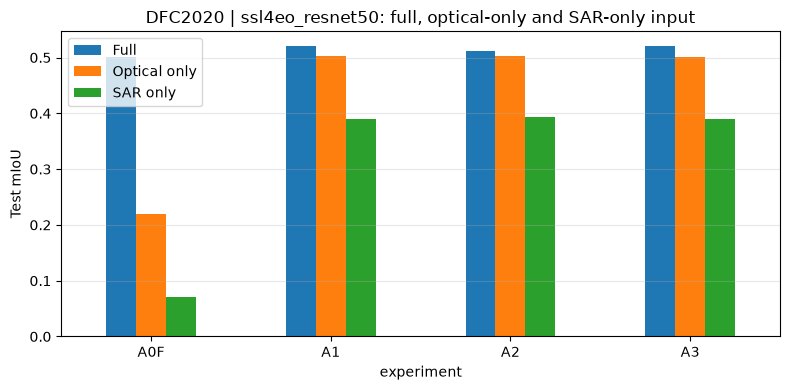

In [8]:
# ============================================================
# CELL 10 — TEST: FULL / OPTICAL-ONLY / SAR-ONLY  (needs Cells 1–5 only)
# ============================================================
ckpts = sorted(CKPT_DIR.glob("A*_s*_best.pt"))
if not ckpts:
    raise RuntimeError("No trained checkpoints in " + str(CKPT_DIR))

summary_rows, per_class_rows = [], []
for path in ckpts:
    model, ck = load_checkpoint(path)
    exp, seed = ck["experiment"], ck["seed"]
    res = {}
    for mode in ["full", "opt", "sar"]:
        m, cm = evaluate(model, test_loader, mode, desc=f"{exp}_s{seed}-{mode}")
        res[mode] = m
        pd.DataFrame(cm.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            OUT_DIR / f"{exp}_s{seed}_{mode}_confusion.csv")
        for c, cname in enumerate(CLASS_NAMES):
            per_class_rows.append({"experiment": exp, "seed": seed, "mode": mode, "class": cname,
                                   "IoU": m["per_class_iou"][c], "F1": m["per_class_f1"][c]})
    full, optm, sarm = res["full"]["mIoU"], res["opt"]["mIoU"], res["sar"]["mIoU"]
    summary_rows.append({
        "experiment": exp, "seed": seed, "best_epoch": ck["epoch"],
        "FULL_mIoU": full, "OPT_mIoU": optm, "SAR_mIoU": sarm,
        "FULL_F1": res["full"]["macroF1"], "OPT_F1": res["opt"]["macroF1"], "SAR_F1": res["sar"]["macroF1"],
        "FULL_OA": res["full"]["OA"], "OPT_OA": res["opt"]["OA"], "SAR_OA": res["sar"]["OA"],
        "PRR_opt_only": optm / (full + 1e-12), "PRR_sar_only": sarm / (full + 1e-12),
        "Robust_mean_mIoU": float(np.mean([full, optm, sarm])),
        "Worst_case_mIoU": float(min(full, optm, sarm))})
    print(f"{exp}_s{seed}: FULL {full:.4f} | OPT-only {optm:.4f} | SAR-only {sarm:.4f}")

results_df = pd.DataFrame(summary_rows)
perclass_df = pd.DataFrame(per_class_rows)
results_df.to_csv(OUT_DIR / "test_results_per_seed.csv", index=False)
perclass_df.to_csv(OUT_DIR / "test_per_class_per_seed.csv", index=False)

metric_cols = [c for c in results_df.columns if c not in ("experiment", "seed", "best_epoch")]
agg = results_df.groupby("experiment")[metric_cols].agg(["mean", "std"])
agg.to_csv(OUT_DIR / "test_results_mean_std.csv")

print("\nMean over seeds (std shown when more than one seed was run):")
main = results_df.groupby("experiment")[["FULL_mIoU", "OPT_mIoU", "SAR_mIoU", "Robust_mean_mIoU",
                                         "Worst_case_mIoU", "PRR_opt_only", "PRR_sar_only"]].mean()
display(main.round(4))
display(perclass_df.groupby(["class", "experiment", "mode"])["IoU"].mean()
        .unstack(["experiment", "mode"]).round(3))

plot_df = results_df.groupby("experiment")[["FULL_mIoU", "OPT_mIoU", "SAR_mIoU"]].mean()
ax = plot_df.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("Test mIoU"); ax.set_title(f"{DATASET} | {BACKBONE}: full, optical-only and SAR-only input")
ax.legend(["Full", "Optical only", "SAR only"]); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "modality_comparison.png", dpi=200); plt.show()

dependency A3_s42_best:   0%|          | 0/62 [00:00<?, ?it/s]

dependency A3_s43_best:   0%|          | 0/62 [00:00<?, ?it/s]

dependency A3_s44_best:   0%|          | 0/62 [00:00<?, ?it/s]

,class,modality,D_true,D_pred,MAE,n
0,barren,optical,0.7547,0.6620,0.1604,1359
1,barren,sar,0.5566,0.4653,0.1764,1359
2,cropland,optical,0.7426,0.7241,0.0905,1929
3,cropland,sar,0.5516,0.4624,0.1435,1929
4,forest,optical,0.7901,0.6952,0.1434,1893
5,forest,sar,0.5799,0.4937,0.1666,1893
6,grassland,optical,0.7418,0.5916,0.2090,2097
7,grassland,sar,0.5813,0.3754,0.2420,2097
8,shrubland,optical,0.7867,0.5802,0.2504,2121
9,shrubland,sar,0.3226,0.3482,0.1490,2121


Spearman correlation (predicted vs interventional dependency):
optical    0.372
sar        0.509


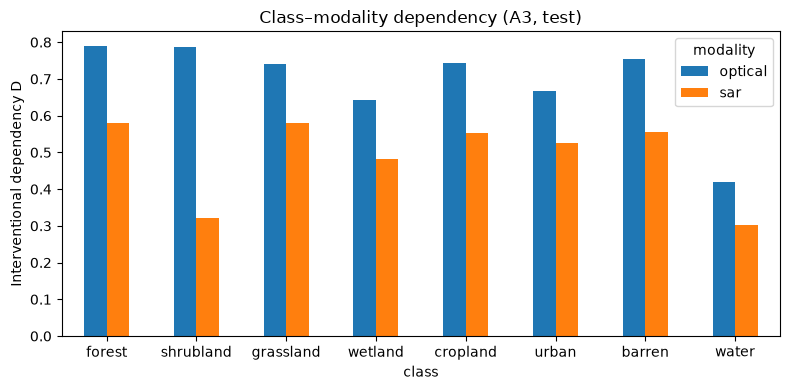

In [10]:
# ============================================================
# CELL 11 — A3 DEPENDENCY ANALYSIS (predicted vs interventional)
# ============================================================
a3_ckpts = sorted(CKPT_DIR.glob("A3_s*_best.pt"))
if not a3_ckpts:
    print("A3 not trained yet — skipping.")
else:
    rows = []
    for path in a3_ckpts:
        model, ck = load_checkpoint(path)
        with torch.no_grad():
            for o, s, y in tqdm(test_loader, desc=f"dependency {path.stem}"):
                o, s, y = o.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
                lf, d_pred = model(o, s, "full", return_dependency=True)
                pf = torch.softmax(lf.float(), 1)
                po = torch.softmax(model(o, s, "opt").float(), 1)
                ps = torch.softmax(model(o, s, "sar").float(), 1)
                d_opt, v_opt = intervention_dependency(pf, ps, y)
                d_sar, v_sar = intervention_dependency(pf, po, y)
                for mi, (dt, vv) in enumerate([(d_opt, v_opt), (d_sar, v_sar)]):
                    b_idx, c_idx = torch.nonzero(vv, as_tuple=True)
                    for b, c in zip(b_idx.tolist(), c_idx.tolist()):
                        rows.append({"seed": ck["seed"], "class": CLASS_NAMES[c],
                                     "modality": ["optical", "sar"][mi],
                                     "D_true": float(dt[b, c]), "D_pred": float(d_pred[b, c, mi])})
    dep_df = pd.DataFrame(rows)
    dep_df["abs_err"] = (dep_df["D_true"] - dep_df["D_pred"]).abs()
    dep_summary = (dep_df.groupby(["class", "modality"])
                   .agg(D_true=("D_true", "mean"), D_pred=("D_pred", "mean"),
                        MAE=("abs_err", "mean"), n=("D_true", "size")).reset_index())
    corr = pd.Series({mod: g["D_true"].corr(g["D_pred"], method="spearman")
                      for mod, g in dep_df.groupby("modality")})
    dep_df.to_csv(OUT_DIR / "A3_dependency_samples.csv", index=False)
    dep_summary.to_csv(OUT_DIR / "A3_dependency_summary.csv", index=False)
    display(dep_summary.round(4))
    print("Spearman correlation (predicted vs interventional dependency):")
    print(corr.round(3).to_string())

    piv = dep_summary.pivot(index="class", columns="modality", values="D_true").reindex(CLASS_NAMES)
    ax = piv.plot.bar(figsize=(8, 4), rot=0)
    ax.set_ylabel("Interventional dependency D"); ax.set_title("Class–modality dependency (A3, test)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "A3_class_dependency.png", dpi=200); plt.show()

A0F_s42_best optical p=0.0:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42_best optical p=0.25:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42_best optical p=0.5:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42_best optical p=0.75:   0%|          | 0/62 [00:00<?, ?it/s]

A0F_s42_best optical p=1.0:   0%|          | 0/62 [00:00<?, ?it/s]

...

A3_s44_best sar p=0.0:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44_best sar p=0.25:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44_best sar p=0.5:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44_best sar p=0.75:   0%|          | 0/62 [00:00<?, ?it/s]

A3_s44_best sar p=1.0:   0%|          | 0/62 [00:00<?, ?it/s]

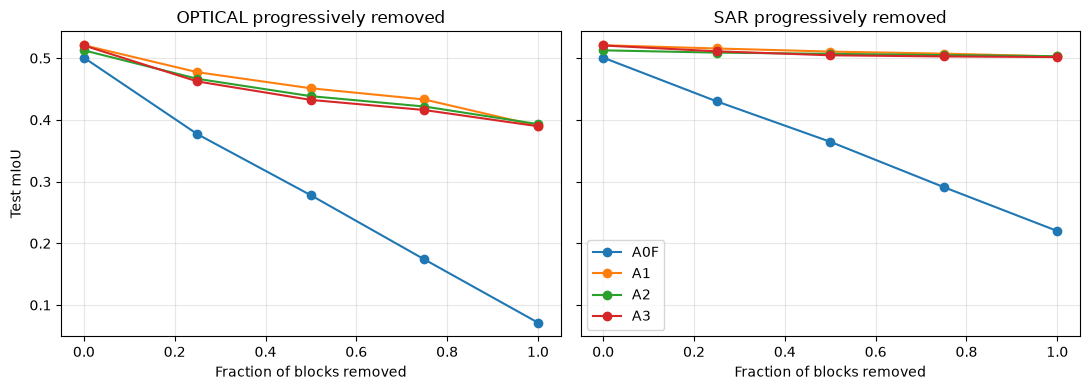

,AUC_optical_degraded,AUC_sar_degraded
experiment,,
A0F,0.2786,0.3614
A1,0.4542,0.5113
A2,0.4448,0.5071
A3,0.4414,0.5074


In [11]:
# ============================================================
# CELL 12 — PROGRESSIVE SENSOR DEGRADATION (Objective 4)
# A fraction p of 32×32 blocks of one modality is blanked (cloud gaps for
# optical, data gaps for SAR). p = 0 is the full input; p = 1 equals the
# fully missing modality. The same block masks are used for every model.
# ============================================================
LEVELS = [0.0, 0.25, 0.5, 0.75, 1.0]
BLOCK = 32

def make_degrader(which, p, seed=2026):
    def degrade(o, s, batch_idx):
        g = torch.Generator(device="cpu").manual_seed(seed + batch_idx)
        B, _, H, W = o.shape
        keep = (torch.rand(B, 1, H // BLOCK, W // BLOCK, generator=g) >= p).float()
        keep = F.interpolate(keep, size=(H, W), mode="nearest").to(o.device)
        return (o * keep, s) if which == "optical" else (o, s * keep)
    return degrade

deg_rows = []
for path in sorted(CKPT_DIR.glob("A*_s*_best.pt")):
    model, ck = load_checkpoint(path)
    for which in ["optical", "sar"]:
        for p in LEVELS:
            m, _ = evaluate(model, test_loader, "full", degrade=make_degrader(which, p),
                            desc=f"{path.stem} {which} p={p}")
            deg_rows.append({"experiment": ck["experiment"], "seed": ck["seed"],
                             "degraded": which, "level": p, "mIoU": m["mIoU"]})

deg_df = pd.DataFrame(deg_rows)
deg_df.to_csv(OUT_DIR / "degradation_results.csv", index=False)
deg_mean = deg_df.groupby(["degraded", "experiment", "level"])["mIoU"].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, which in zip(axes, ["optical", "sar"]):
    for exp in sorted(deg_mean["experiment"].unique()):
        d = deg_mean[(deg_mean["degraded"] == which) & (deg_mean["experiment"] == exp)]
        ax.plot(d["level"], d["mIoU"], marker="o", label=exp)
    ax.set_title(f"{which.upper()} progressively removed")
    ax.set_xlabel("Fraction of blocks removed"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Test mIoU"); axes[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "degradation_curves.png", dpi=200); plt.show()

# Area under the degradation curve (higher = more robust)
def _area(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))

auc = pd.DataFrame([{"experiment": e, f"AUC_{w}_degraded": _area(d["level"], d["mIoU"])}
                    for (w, e), d in deg_mean.groupby(["degraded", "experiment"])])
auc = auc.groupby("experiment").first().round(4)
auc.to_csv(OUT_DIR / "degradation_auc.csv")
display(auc)

failure forecast A3_s42_best:   0%|          | 0/62 [00:00<?, ?it/s]

failure forecast A3_s43_best:   0%|          | 0/62 [00:00<?, ?it/s]

failure forecast A3_s44_best:   0%|          | 0/62 [00:00<?, ?it/s]

Class-level tests use: ['barren', 'cropland', 'forest', 'grassland', 'shrubland', 'urban', 'water', 'wetland']


,class,removed,D_pred_mean,IoU_full,IoU_after_removal,IoU_drop
0,barren,optical,0.6620,0.5985,0.4284,0.1700
1,barren,sar,0.4653,0.5985,0.5930,0.0055
2,cropland,optical,0.7241,0.5141,0.3180,0.1961
3,cropland,sar,0.4624,0.5141,0.5362,-0.0221
4,forest,optical,0.6952,0.6778,0.5359,0.1419
5,forest,sar,0.4937,0.6778,0.5561,0.1217
6,grassland,optical,0.5916,0.1747,0.0112,0.1635
7,grassland,sar,0.3755,0.1747,0.1981,-0.0234
8,shrubland,optical,0.5802,0.3612,0.1546,0.2066
9,shrubland,sar,0.3482,0.3612,0.3429,0.0182


,test,value
0,"Class level: D_pred vs IoU drop (Spearman, 16 ...",0.703
1,optical removed,-0.167
2,SAR removed,0.500
3,Instance level: D_pred vs recall drop (Spearma...,0.435
4,mean WITHIN-class Spearman (beyond class id...,0.207
5,"Failure detection AUROC (recall drop > 0.20), ...",0.802
6,optical removed,0.698
7,SAR removed,0.698


D_pred vs class-only baselines (AUROC):


,removed,fail_rate,AUROC_D_pred,AUROC_class_avg_D,AUROC_oracle_class_prior
0,optical,0.331,0.698,0.612,0.754
1,sar,0.051,0.698,0.639,0.717


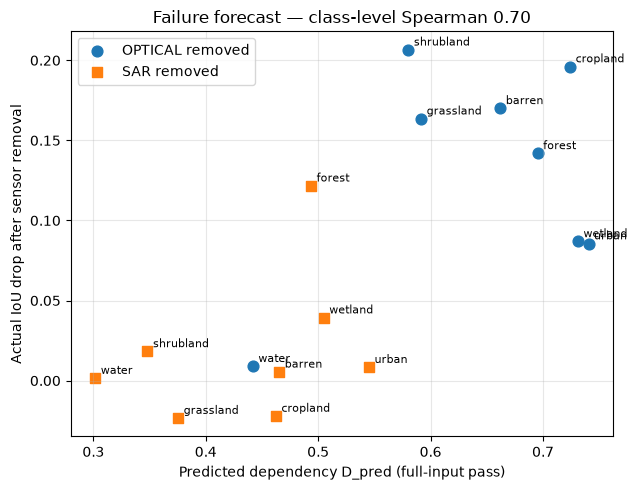

How to read this:
  Within-class Spearman > ~0.3 and AUROC > ~0.70 -> D_pred is a usable failure forecast (strong paper hook).
  High class-level but ~0 within-class -> it only knows class averages (still reportable, weaker).
  Near 0 everywhere -> D_pred describes dependency but does not forecast damage; rethink the hook.


In [12]:
# ============================================================
# CELL 13 — DOES PREDICTED DEPENDENCY FORECAST SENSOR-FAILURE DAMAGE?
# Run after Cells 1–5. No training.
#
# Question for the paper: from ONE full-input forward pass, can D_pred
# tell us which classes (and which image patches) will lose accuracy if
# the optical or the SAR sensor fails?
#   removing OPTICAL -> SAR-only prediction  <-> D_pred[..., 0]
#   removing SAR     -> optical-only prediction <-> D_pred[..., 1]
# ============================================================
FORECAST_GLOB = "A3_s*_best.pt"
MIN_PIXELS = 256          # ignore class instances smaller than this in a patch (too noisy)
MIN_IOU_FULL = 0.10       # class-level tests skip classes the model barely segments (e.g. "others")
FAIL_THRESHOLD = 0.20     # "failure" = class recall drops by more than 20 points

def auroc(scores, labels):
    """Probability that a failing instance gets a higher score than a non-failing one."""
    labels = np.asarray(labels, bool)
    n1, n0 = labels.sum(), (~labels).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(np.asarray(scores)).rank().values
    return float((r[labels].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

a3_ckpts = sorted(CKPT_DIR.glob(FORECAST_GLOB))
if not a3_ckpts:
    raise RuntimeError(f"No {FORECAST_GLOB} checkpoint found in {CKPT_DIR}")

inst_rows, class_rows = [], []
for path in a3_ckpts:
    model, ck = load_checkpoint(path)
    seed = ck["seed"]
    cms = {m: torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64) for m in ["full", "opt", "sar"]}
    dsum = torch.zeros(NUM_CLASSES, 2); dcnt = torch.zeros(NUM_CLASSES)
    with torch.no_grad():
        for o, s, y in tqdm(test_loader, desc=f"failure forecast {path.stem}"):
            o, s, y = o.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
            lf, d_pred = model(o, s, "full", return_dependency=True)
            preds = {"full": lf.argmax(1), "opt": model(o, s, "opt").argmax(1), "sar": model(o, s, "sar").argmax(1)}
            valid = y != IGNORE_INDEX
            for m, p in preds.items():
                cms[m] += torch.bincount(y[valid] * NUM_CLASSES + p[valid],
                                         minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES).cpu()
            d_cpu = d_pred.float().cpu()
            for c in range(NUM_CLASSES):
                mask = (y == c)
                cnt = mask.sum((1, 2))
                present = torch.nonzero(cnt > 0).flatten().tolist()
                for b in present:
                    dsum[c] += d_cpu[b, c]; dcnt[c] += 1
                    n = int(cnt[b])
                    if n < MIN_PIXELS:
                        continue
                    rec = {m: float(((p[b] == c) & mask[b]).sum()) / n for m, p in preds.items()}
                    inst_rows.append({"seed": seed, "class": CLASS_NAMES[c], "removed": "optical",
                                      "D_pred": float(d_cpu[b, c, 0]), "recall_drop": rec["full"] - rec["sar"]})
                    inst_rows.append({"seed": seed, "class": CLASS_NAMES[c], "removed": "sar",
                                      "D_pred": float(d_cpu[b, c, 1]), "recall_drop": rec["full"] - rec["opt"]})

    iou = {m: np.array(metrics_from_confusion(cm)["per_class_iou"]) for m, cm in cms.items()}
    for c, cname in enumerate(CLASS_NAMES):
        for mi, removed, kept in [(0, "optical", "sar"), (1, "sar", "opt")]:
            class_rows.append({"seed": seed, "class": cname, "removed": removed,
                               "D_pred_mean": float(dsum[c, mi] / max(dcnt[c], 1)),
                               "IoU_full": iou["full"][c], "IoU_after_removal": iou[kept][c],
                               "IoU_drop": iou["full"][c] - iou[kept][c]})

inst_df = pd.DataFrame(inst_rows)
class_df = (pd.DataFrame(class_rows)
            .groupby(["class", "removed"], as_index=False)
            [["D_pred_mean", "IoU_full", "IoU_after_removal", "IoU_drop"]].mean())
inst_df.to_csv(OUT_DIR / f"failure_forecast_instances_{FORECAST_GLOB.split('_')[0]}.csv", index=False)
class_df.to_csv(OUT_DIR / f"failure_forecast_classes_{FORECAST_GLOB.split('_')[0]}.csv", index=False)

# ---- 1. Class level: does D_pred rank classes by how much they lose? ----
cls_eval = class_df[class_df["IoU_full"] >= MIN_IOU_FULL]
print("Class-level tests use:", sorted(cls_eval["class"].unique()))
cls_rho = cls_eval["D_pred_mean"].corr(cls_eval["IoU_drop"], method="spearman")
cls_rho_by_mod = {m: g["D_pred_mean"].corr(g["IoU_drop"], method="spearman")
                  for m, g in cls_eval.groupby("removed")}

# ---- 2. Instance level: does D_pred rank individual patches? ----
inst_rho = inst_df["D_pred"].corr(inst_df["recall_drop"], method="spearman")
within = [g["D_pred"].corr(g["recall_drop"], method="spearman")
          for _, g in inst_df.groupby(["class", "removed"]) if len(g) >= 20]
within_rho = float(np.nanmean(within)) if within else np.nan

# ---- 3. Failure detection: can D_pred flag instances that will fail? ----
fail = inst_df["recall_drop"] > FAIL_THRESHOLD
auc_all = auroc(inst_df["D_pred"], fail)
auc_by_mod = {m: auroc(g["D_pred"], g["recall_drop"] > FAIL_THRESHOLD) for m, g in inst_df.groupby("removed")}

# ---- 4. Does D_pred beat knowing only the class? ----
# class-avg D  : replace each instance's D_pred with its class mean (what a class lookup table gives)
# oracle prior : each class's TRUE mean damage on the test set (an upper bound for any class-only rule)
base_rows = []
for m, g in inst_df.groupby("removed"):
    f = g["recall_drop"] > FAIL_THRESHOLD
    base_rows.append({"removed": m, "fail_rate": f.mean(),
                      "AUROC_D_pred": auroc(g["D_pred"], f),
                      "AUROC_class_avg_D": auroc(g.groupby("class")["D_pred"].transform("mean"), f),
                      "AUROC_oracle_class_prior": auroc(g.groupby("class")["recall_drop"].transform("mean"), f)})
baseline_df = pd.DataFrame(base_rows)
baseline_df.to_csv(OUT_DIR / f"failure_forecast_vs_class_prior_{FORECAST_GLOB.split('_')[0]}.csv", index=False)

summary = pd.DataFrame([
    {"test": f"Class level: D_pred vs IoU drop (Spearman, {len(cls_eval)} points)", "value": cls_rho},
    {"test": "   optical removed", "value": cls_rho_by_mod.get("optical")},
    {"test": "   SAR removed", "value": cls_rho_by_mod.get("sar")},
    {"test": f"Instance level: D_pred vs recall drop (Spearman, n={len(inst_df)})", "value": inst_rho},
    {"test": "   mean WITHIN-class Spearman (beyond class identity)", "value": within_rho},
    {"test": f"Failure detection AUROC (recall drop > {FAIL_THRESHOLD:.2f}), failure rate {fail.mean():.1%}", "value": auc_all},
    {"test": "   optical removed", "value": auc_by_mod.get("optical")},
    {"test": "   SAR removed", "value": auc_by_mod.get("sar")},
])
tagname = FORECAST_GLOB.split("_")[0]
summary.to_csv(OUT_DIR / f"failure_forecast_summary_{tagname}.csv", index=False)
display(class_df.round(4))
display(summary.round(3))
print("D_pred vs class-only baselines (AUROC):")
display(baseline_df.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5))
for removed, marker in [("optical", "o"), ("sar", "s")]:
    d = class_df[class_df["removed"] == removed]
    ax.scatter(d["D_pred_mean"], d["IoU_drop"], marker=marker, s=60, label=f"{removed.upper()} removed")
    for _, r in d.iterrows():
        ax.annotate(r["class"], (r["D_pred_mean"], r["IoU_drop"]), fontsize=8,
                    xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Predicted dependency D_pred (full-input pass)")
ax.set_ylabel("Actual IoU drop after sensor removal")
ax.set_title(f"Failure forecast — class-level Spearman {cls_rho:.2f}")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / f"failure_forecast_scatter_{FORECAST_GLOB.split('_')[0]}.png", dpi=200); plt.show()

print("How to read this:")
print("  Within-class Spearman > ~0.3 and AUROC > ~0.70 -> D_pred is a usable failure forecast (strong paper hook).")
print("  High class-level but ~0 within-class -> it only knows class averages (still reportable, weaker).")
print("  Near 0 everywhere -> D_pred describes dependency but does not forecast damage; rethink the hook.")

In [13]:
# ============================================================
# CELL 14 — PACKAGE ALL RESULTS FOR THE PAPER (no checkpoints)
# ============================================================
PKG = OUT_DIR / "paper_package"
PKG.mkdir(exist_ok=True)
n = 0
for f in OUT_DIR.iterdir():
    if f.is_file() and f.suffix in (".csv", ".png", ".json"):
        shutil.copy2(f, PKG / f.name); n += 1
zip_path = shutil.make_archive(str(ROOT / f"{OUT_DIR.name}_results"), "zip", PKG)
print(f"{n} files -> {zip_path}")

80 files -> F:\JShanthini\content\CIMD_v3_DFC2020_ssl4eo_resnet50_results.zip


# Part 2 — Reviewer experiments (v4)
Run **after Cells 1–6** (bfloat16 and the NaN guard are already built into this notebook). These cells add:
- **E1** failure-forecast comparison against uncertainty baselines (no training, ~45 min for 3 seeds)
- **E2** three published-style comparison methods: knowledge distillation (B_KD), feature reconstruction / hallucination (B_REC), gated adaptive fusion (B_GATE)
- **E3** one evaluation table for every trained model (cached, so it can be rerun safely)
- **E4** optional: A2 (uniform consistency) on this dataset

Nothing here deletes files. All new checkpoints are saved next to the existing ones.

In [7]:
# ============================================================
# CELL E0 — v4 MODEL VARIANTS AND LOSSES (run once per session, after Cells 1–6)
# ============================================================
if "AMP_DTYPE" not in globals():
    raise RuntimeError("Run Cells 1–6 first (Cell 1 defines AMP_DTYPE).")

EXPERIMENTS.update({
    "B_KD":   "Comparison: one-way knowledge distillation (full -> missing)",
    "B_REC":  "Comparison: feature reconstruction (missing-modality hallucination)",
    "B_GATE": "Comparison: gated adaptive fusion + missing-modality training",
})
VARIANT_OF = {"B_REC": "rec", "B_GATE": "gate"}      # everything else uses the plain architecture
MODEL_VARIANT = "base"
GAMMA_KD = 0.5          # distillation weight (same value as the earlier one-way KD sweep)
LAMBDA_REC = 1.0        # feature-reconstruction weight

class Hallucinator(nn.Module):
    """Predicts one sensor's encoder features from the other sensor's features at the same level."""
    def __init__(self, c):
        super().__init__()
        mid = max(64, min(256, c // 2))
        self.net = nn.Sequential(
            nn.Conv2d(c, mid, 1, bias=False), nn.GroupNorm(GN_GROUPS, mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, mid, 3, padding=1, bias=False), nn.GroupNorm(GN_GROUPS, mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, c, 1))
    def forward(self, x):
        return self.net(x)

class DualStreamSegV4(DualStreamSeg):
    """Same backbone/decoder as A0F–A3; optional hallucination ('rec') or gated fusion ('gate')."""
    def __init__(self, opt_ch, sar_ch, ncls, load_weights=True, variant="base"):
        super().__init__(opt_ch, sar_ch, ncls, load_weights)
        self.variant = variant
        if variant == "rec":
            self.o2s = nn.ModuleList([Hallucinator(c) for c in self.ENC_CH])
            self.s2o = nn.ModuleList([Hallucinator(c) for c in self.ENC_CH])
        if variant == "gate":
            self.gates = nn.ModuleList([nn.Sequential(nn.Conv2d(2 * c, 64, 1, bias=False), nn.GroupNorm(GN_GROUPS, 64),
                                                      nn.ReLU(inplace=True), nn.Conv2d(64, 2, 1)) for c in self.ENC_CH])

    def encode(self, optical, sar, mode):
        if self.variant == "rec" and mode == "opt":            # SAR missing -> hallucinate SAR features
            fo = self.opt_encoder(optical)
            return fo, [h(f) for h, f in zip(self.o2s, fo)]
        if self.variant == "rec" and mode == "sar":            # optical missing -> hallucinate optical features
            fs = self.sar_encoder(sar)
            return [h(f) for h, f in zip(self.s2o, fs)], fs
        if mode == "opt":
            sar = torch.zeros_like(sar)
        elif mode == "sar":
            optical = torch.zeros_like(optical)
        elif mode != "full":
            raise ValueError(mode)
        return self.opt_encoder(optical), self.sar_encoder(sar)

    def _fuse(self, i, a, b):
        if self.variant == "gate":
            g = 2.0 * torch.softmax(self.gates[i](torch.cat([a, b], 1)).float(), 1).to(a.dtype)   # = 1 at initialisation
            a, b = a * g[:, 0:1], b * g[:, 1:2]
        return self.lateral[i](torch.cat([a, b], 1))

    def decode(self, fo, fs, out_hw):
        p = self.smooth[3](self._fuse(3, fo[3], fs[3]))
        for i in (2, 1, 0):
            lat = self._fuse(i, fo[i], fs[i])
            p = self.smooth[i](lat + F.interpolate(p, size=lat.shape[-2:], mode="bilinear", align_corners=False))
        return F.interpolate(self.seg_head(p), size=out_hw, mode="bilinear", align_corners=False)

    def forward(self, optical, sar, mode="full", return_dependency=False):
        fo, fs = self.encode(optical, sar, mode)
        logits = self.decode(fo, fs, optical.shape[-2:])
        if return_dependency:
            dep = torch.sigmoid(self.dep_head(torch.cat([fo[3], fs[3]], 1)).float()).view(-1, self.ncls, 2)
            return logits, dep
        return logits

def make_model(load_weights=True):
    return DualStreamSegV4(OPT_CH, SAR_CH, NUM_CLASSES, load_weights, variant=MODEL_VARIANT).to(DEVICE)

def load_checkpoint(path):
    global MODEL_VARIANT
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    old = MODEL_VARIANT
    MODEL_VARIANT = VARIANT_OF.get(ck.get("experiment", ""), "base")
    try:
        model = make_model(load_weights=False)                # weights come from the checkpoint
    finally:
        MODEL_VARIANT = old
    state = {k: v for k, v in ck["model"].items()
             if not (k.startswith("opt_encoder.net.fc.") or k.startswith("sar_encoder.net.fc."))}
    model.load_state_dict(state)                              # unused classifier head removed
    model.eval()
    return model, ck

def _classwise_kl(p_teacher, logits_student, y):
    logp = F.log_softmax(logits_student.float(), 1)
    kl = (p_teacher * (torch.log(p_teacher + 1e-8) - logp)).sum(1)
    vals, valid = [], []
    for c in range(NUM_CLASSES):
        m = (y == c).float(); cnt = m.sum((1, 2))
        vals.append((kl * m).sum((1, 2)) / (cnt + 1e-8)); valid.append(cnt > 0)
    return torch.stack(vals, 1), torch.stack(valid, 1)

def _norm_mse(pred, target):
    t = target.detach().float()
    return F.mse_loss(pred.float(), t) / (t.pow(2).mean() + 1e-6)

if "_pre_v4_compute_loss" not in globals():
    _pre_v4_compute_loss = compute_loss

def compute_loss(name, model, optical, sar, y):
    if name == "B_KD":
        lf, lo, ls = model(optical, sar, "full"), model(optical, sar, "opt"), model(optical, sar, "sar")
        loss = segmentation_loss(lf, y) + ALPHA * (segmentation_loss(lo, y) + segmentation_loss(ls, y))
        pt = torch.softmax(lf.float(), 1).detach()                       # teacher = full-input prediction
        k1, v1 = _classwise_kl(pt, ls, y); k2, v2 = _classwise_kl(pt, lo, y)
        kl, valid = torch.stack([k1, k2], 2), torch.stack([v1, v2], 2)
        return loss + GAMMA_KD * weighted_class_response_loss(kl, torch.ones_like(kl), valid)
    if name == "B_REC":
        fo, fs = model.opt_encoder(optical), model.sar_encoder(sar)
        hw = optical.shape[-2:]
        fs_hat = [h(f) for h, f in zip(model.o2s, fo)]
        fo_hat = [h(f) for h, f in zip(model.s2o, fs)]
        l_rec = sum(_norm_mse(a, b) for a, b in zip(fs_hat, fs)) + sum(_norm_mse(a, b) for a, b in zip(fo_hat, fo))
        lf = model.decode(fo, fs, hw)
        lo = model.decode(fo, fs_hat, hw)                                # SAR missing
        ls = model.decode(fo_hat, fs, hw)                                # optical missing
        loss = segmentation_loss(lf, y) + ALPHA * (segmentation_loss(lo, y) + segmentation_loss(ls, y))
        return loss + LAMBDA_REC * l_rec / (2 * len(fo))
    if name == "B_GATE":
        return _pre_v4_compute_loss("A1", model, optical, sar, y)       # A1 objective, gated architecture
    return _pre_v4_compute_loss(name, model, optical, sar, y)

def run_experiment(name, seed):
    """Use this instead of train_experiment for every v4 run (selects the right architecture)."""
    global MODEL_VARIANT
    MODEL_VARIANT = VARIANT_OF.get(name, "base")
    try:
        return train_experiment(name, seed)
    finally:
        MODEL_VARIANT = "base"

print("v4 ready | AMP:", AMP_DTYPE, "| experiments:", list(EXPERIMENTS))

v4 ready | AMP: torch.bfloat16 | experiments: ['A0F', 'A1', 'A2', 'A3', 'B_KD', 'B_REC', 'B_GATE']


In [11]:
# ============================================================
# CELL E1 — FAILURE FORECAST vs UNCERTAINTY BASELINES (no training)
# Compares D_pred with the model's own confidence (max-softmax, entropy, margin)
# for predicting which class instances lose >20 points of recall when a sensor is removed.
# ============================================================
E1_GLOB = "A3_s*_best.pt"
E1_MIN_PIXELS = 256
E1_FAIL = 0.20

def _auroc(scores, labels):
    labels = np.asarray(labels, bool); n1, n0 = labels.sum(), (~labels).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(np.asarray(scores)).rank().values
    return float((r[labels].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

rows = []
for path in sorted(CKPT_DIR.glob(E1_GLOB)):
    model, ck = load_checkpoint(path)
    with torch.no_grad():
        for o, s, y in tqdm(test_loader, desc=f"E1 {path.stem}"):
            o, s, y = o.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=USE_AMP):
                lf, d_pred = model(o, s, "full", return_dependency=True)
                lo, ls = model(o, s, "opt"), model(o, s, "sar")
            pf = torch.softmax(lf.float(), 1)
            maxp = pf.max(1).values
            ent = -(pf * torch.log(pf + 1e-8)).sum(1) / np.log(NUM_CLASSES)
            top2 = pf.topk(2, 1).values; margin = top2[:, 0] - top2[:, 1]
            pr = {"full": lf.argmax(1), "opt": lo.argmax(1), "sar": ls.argmax(1)}
            d_cpu = d_pred.float().cpu()
            for c in range(NUM_CLASSES):
                mask = (y == c); cnt = mask.sum((1, 2))
                for b in torch.nonzero(cnt >= E1_MIN_PIXELS).flatten().tolist():
                    mb, n = mask[b], int(cnt[b])
                    rec = {k: float(((v[b] == c) & mb).sum()) / n for k, v in pr.items()}
                    unc = {"U_maxprob": 1 - float(maxp[b][mb].mean()), "U_entropy": float(ent[b][mb].mean()),
                           "U_margin": 1 - float(margin[b][mb].mean())}
                    for mi, removed, kept in [(0, "optical", "sar"), (1, "sar", "opt")]:
                        rows.append({"seed": ck["seed"], "class": CLASS_NAMES[c], "removed": removed,
                                     "D_pred": float(d_cpu[b, c, mi]), "recall_drop": rec["full"] - rec[kept], **unc})

e1 = pd.DataFrame(rows)
e1["fail"] = e1["recall_drop"] > E1_FAIL
e1["class_avg_D"] = e1.groupby(["seed", "removed", "class"])["D_pred"].transform("mean")
e1["D_pred+entropy"] = e1.groupby(["seed", "removed"])["D_pred"].rank(pct=True) + \
                       e1.groupby(["seed", "removed"])["U_entropy"].rank(pct=True)
e1.to_csv(OUT_DIR / "E1_forecast_vs_uncertainty_instances.csv", index=False)

scores = ["D_pred", "class_avg_D", "U_maxprob", "U_entropy", "U_margin", "D_pred+entropy"]
tab = []
for (seed, rem), g in e1.groupby(["seed", "removed"]):
    tab.append({"seed": seed, "removed": rem, "fail_rate": g["fail"].mean(),
                **{f"AUROC_{k}": _auroc(g[k], g["fail"]) for k in scores}})
tab = pd.DataFrame(tab)
summary = tab.groupby("removed")[[c for c in tab.columns if c.startswith("AUROC_")]].agg(["mean", "std"])

# bootstrap: D_pred minus the best single uncertainty score (pooled over seeds)
rng = np.random.default_rng(0)
ci_rows = []
for rem, g in e1.groupby("removed"):
    g = g.reset_index(drop=True)
    best_u = max(["U_maxprob", "U_entropy", "U_margin"], key=lambda k: _auroc(g[k], g["fail"]))
    diffs = []
    for _ in range(500):
        ix = rng.integers(0, len(g), len(g)); sg = g.iloc[ix]
        diffs.append(_auroc(sg["D_pred"], sg["fail"]) - _auroc(sg[best_u], sg["fail"]))
    lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5])
    ci_rows.append({"removed": rem, "best_uncertainty": best_u,
                    "AUROC_D_pred": _auroc(g["D_pred"], g["fail"]), f"AUROC_best_uncertainty": _auroc(g[best_u], g["fail"]),
                    "difference": _auroc(g["D_pred"], g["fail"]) - _auroc(g[best_u], g["fail"]),
                    "CI95_low": lo_ci, "CI95_high": hi_ci})
ci = pd.DataFrame(ci_rows)
tab.to_csv(OUT_DIR / "E1_forecast_vs_uncertainty_per_seed.csv", index=False)
summary.to_csv(OUT_DIR / "E1_forecast_vs_uncertainty_summary.csv")
ci.to_csv(OUT_DIR / "E1_Dpred_vs_best_uncertainty_CI.csv", index=False)
print("Failure-detection AUROC (mean ± std over seeds):"); display(summary.round(3))
print("D_pred minus best uncertainty score (95% bootstrap CI, pooled):"); display(ci.round(3))

E1 A3_s42_best:   0%|          | 0/62 [00:00<?, ?it/s]

E1 A3_s43_best:   0%|          | 0/62 [00:00<?, ?it/s]

E1 A3_s44_best:   0%|          | 0/62 [00:00<?, ?it/s]

Failure-detection AUROC (mean ± std over seeds):


AUROC_D_pred        AUROC_class_avg_D        AUROC_U_maxprob         \
                mean    std              mean    std            mean    std   
removed                                                                       
optical        0.698  0.072             0.608  0.064           0.581  0.035   
sar            0.688  0.072             0.682  0.087           0.687  0.059   

        AUROC_U_entropy        AUROC_U_margin        AUROC_D_pred+entropy  \
                   mean    std           mean    std                 mean   
removed                                                                     
optical           0.576  0.036          0.583  0.031                0.673   
sar               0.670  0.070          0.698  0.055                0.738   

                
           std  
removed         
optical  0.081  
sar      0.046

D_pred minus best uncertainty score (95% bootstrap CI, pooled):


,removed,best_uncertainty,AUROC_D_pred,AUROC_best_uncertainty,difference,CI95_low,CI95_high
0,optical,U_margin,0.696,0.583,0.113,0.099,0.126
1,sar,U_margin,0.699,0.690,0.009,-0.021,0.035


In [13]:
# ============================================================
# CELL E2 — TRAIN THE THREE COMPARISON METHODS (3 seeds each, ~7.5 h on DFC2020)
# Alternates methods per seed, so stopping early still leaves matched sets.
# Resume-safe: rerun after any interruption (after Cells 1–6 and Cell E0).
# ============================================================
E2_METHODS = ["B_KD", "B_REC", "B_GATE"]       # drop "B_GATE" first if time is short
for s in SEEDS:
    for name in E2_METHODS:
        run_experiment(name, s)

Resuming B_KD_s42 from epoch 2
TRAINING B_KD_s42 — Comparison: one-way knowledge distillation (full -> missing) | ssl4eo_resnet50


B_KD_s42 ep02:   0%|          | 0/544 [00:00<?, ?it/s]

eval-full:   0%|          | 0/49 [00:00<?, ?it/s]

eval-opt:   0%|          | 0/49 [00:00<?, ?it/s]

eval-sar:   0%|          | 0/49 [00:00<?, ?it/s]

...

eval-sar:   0%|          | 0/49 [00:00<?, ?it/s]

B_GATE_s44 ep12 | loss 1.358 | val FULL 0.6588 OPT 0.6416 SAR 0.5191 | robust 0.6065 *best* | 1.9 min


B_GATE_s44 ep13:   0%|          | 0/544 [00:00<?, ?it/s]

eval-full:   0%|          | 0/49 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [14]:
# ============================================================
# CELL E3 — EVALUATE EVERY TRAINED MODEL (full / optical-only / SAR-only + degradation)
# Results are cached per checkpoint in E3_eval_cache.csv, so this can be rerun safely.
# At 100 % removal the explicit missing-modality mode is used (needed for B_REC).
# ============================================================
E3_LEVELS = [0.0, 0.25, 0.5, 0.75, 1.0]
E3_BLOCK = 32
cache_path = OUT_DIR / "E3_eval_cache.csv"
cache = pd.read_csv(cache_path) if cache_path.exists() else pd.DataFrame()

def _degrade(which, p, seed=2026):
    def f(o, s, bi):
        g = torch.Generator(device="cpu").manual_seed(seed + bi)
        B, _, H, W = o.shape
        keep = (torch.rand(B, 1, H // E3_BLOCK, W // E3_BLOCK, generator=g) >= p).float()
        keep = F.interpolate(keep, size=(H, W), mode="nearest").to(o.device)
        return (o * keep, s) if which == "optical" else (o, s * keep)
    return f

for path in sorted(CKPT_DIR.glob("*_s*_best.pt")):
    tag = path.stem.replace("_best", "")
    if len(cache) and (cache["tag"] == tag).any():
        continue
    model, ck = load_checkpoint(path)
    r = {"tag": tag, "experiment": ck["experiment"], "seed": ck["seed"], "best_epoch": ck["epoch"]}
    for mode in ["full", "opt", "sar"]:
        m, _ = evaluate(model, test_loader, mode, desc=f"{tag}-{mode}")
        r[f"{mode.upper()}_mIoU"] = m["mIoU"]; r[f"{mode.upper()}_OA"] = m["OA"]; r[f"{mode.upper()}_F1"] = m["macroF1"]
    for which in ["optical", "sar"]:
        for p in E3_LEVELS:
            if p == 0.0:
                v = r["FULL_mIoU"]
            elif p == 1.0:
                v = r["SAR_mIoU"] if which == "optical" else r["OPT_mIoU"]
            else:
                v = evaluate(model, test_loader, "full", degrade=_degrade(which, p), desc=f"{tag} {which} {p}")[0]["mIoU"]
            r[f"deg_{which}_{p:g}"] = v
    cache = pd.concat([cache, pd.DataFrame([r])], ignore_index=True)
    cache.to_csv(cache_path, index=False)
    print(f"{tag}: FULL {r['FULL_mIoU']:.4f} | OPT {r['OPT_mIoU']:.4f} | SAR {r['SAR_mIoU']:.4f}")

def _area(vals):
    x = np.array(E3_LEVELS); y = np.array(vals)
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))

cache["Robust_mean"] = cache[["FULL_mIoU", "OPT_mIoU", "SAR_mIoU"]].mean(1)
cache["AUC_optical_degraded"] = cache[[f"deg_optical_{p:g}" for p in E3_LEVELS]].apply(_area, axis=1)
cache["AUC_sar_degraded"] = cache[[f"deg_sar_{p:g}" for p in E3_LEVELS]].apply(_area, axis=1)
cols = ["FULL_mIoU", "OPT_mIoU", "SAR_mIoU", "Robust_mean", "AUC_optical_degraded", "AUC_sar_degraded"]
table = cache.groupby("experiment")[cols].agg(["mean", "std"])
order = [e for e in ["A0F", "A1", "A2", "A3", "B_KD", "B_REC", "B_GATE"] if e in table.index]
table = table.loc[order]
table.to_csv(OUT_DIR / "E3_all_methods_mean_std.csv")
print("All methods, test set (mean ± std over seeds):"); display(table.round(4))

# paired differences against A1 (same seeds)
if "A1" in cache["experiment"].values:
    a1 = cache[cache.experiment == "A1"].set_index("seed")[cols]
    diff_rows = []
    for e in order:
        if e == "A1":
            continue
        d = cache[cache.experiment == e].set_index("seed")[cols]
        common = d.index.intersection(a1.index)
        if len(common):
            dd = d.loc[common] - a1.loc[common]
            diff_rows.append({"experiment": e, "seeds": len(common),
                              **{f"{c}_minus_A1": dd[c].mean() for c in cols},
                              "seeds_better_robust": int((dd["Robust_mean"] > 0).sum())})
    diff = pd.DataFrame(diff_rows)
    diff.to_csv(OUT_DIR / "E3_paired_vs_A1.csv", index=False)
    print("Paired difference vs A1 (positive = better than A1):"); display(diff.round(4))

A2_s42-full:   0%|          | 0/62 [00:00<?, ?it/s]

A2_s42-opt:   0%|          | 0/62 [00:00<?, ?it/s]

A2_s42-sar:   0%|          | 0/62 [00:00<?, ?it/s]

A2_s42 optical 0.25:   0%|          | 0/62 [00:00<?, ?it/s]

A2_s42 optical 0.5:   0%|          | 0/62 [00:00<?, ?it/s]

...

A2_s44: FULL 0.4958 | OPT 0.4808 | SAR 0.4019
All methods, test set (mean ± std over seeds):


C:\Users\Admin\AppData\Local\Temp\ipykernel_25652\1819587550.py:46: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  cache["Robust_mean"] = cache[["FULL_mIoU", "OPT_mIoU", "SAR_mIoU"]].mean(1)


FULL_mIoU         OPT_mIoU         SAR_mIoU         Robust_mean  \
                mean     std     mean     std     mean     std        mean   
experiment                                                                   
A0F           0.5008  0.0520   0.2199  0.1180   0.0715  0.0548      0.2641   
A1            0.5209  0.0151   0.5027  0.0206   0.3903  0.0099      0.4713   
A2            0.5126  0.0153   0.5031  0.0194   0.3931  0.0087      0.4696   
A3            0.5205  0.0180   0.5017  0.0120   0.3896  0.0033      0.4706   
B_KD          0.5173  0.0015   0.4961  0.0151   0.3928  0.0084      0.4687   
B_REC         0.5158  0.0163   0.5252  0.0201   0.3840  0.0225      0.4750   
B_GATE        0.5000  0.0022   0.4921  0.0068   0.3775  0.0229      0.4565   

                   AUC_optical_degraded         AUC_sar_degraded          
               std                 mean     std             mean     std  
experiment                                                                
A0F         0.0306               0.2786  0.0240           0.3614  0.0751  
A1          0.0102               0.4542  0.0111           0.5113  0.0168  
A2          0.0088               0.4448  0.0068           0.5071  0.0161  
A3          0.0109               0.4414  0.0123           0.5074  0.0146  
B_KD        0.0032               0.4471  0.0043           0.5027  0.0067  
B_REC       0.0165               0.3438  0.0066           0.4243  0.0252  
B_GATE      0.0105               0.4210  0.0122           0.4946  0.0039

Paired difference vs A1 (positive = better than A1):


,experiment,seeds,FULL_mIoU_minus_A1,OPT_mIoU_minus_A1,SAR_mIoU_minus_A1,Robust_mean_minus_A1,AUC_optical_degraded_minus_A1,AUC_sar_degraded_minus_A1,seeds_better_robust
0,A0F,3,-0.0202,-0.2828,-0.3188,-0.2072,-0.1756,-0.1499,0
1,A2,3,-0.0083,0.0004,0.0028,-0.0017,-0.0094,-0.0042,0
2,A3,3,-0.0005,-0.0010,-0.0007,-0.0007,-0.0129,-0.0040,2
3,B_KD,3,-0.0037,-0.0066,0.0026,-0.0026,-0.0071,-0.0086,1
4,B_REC,3,-0.0051,0.0226,-0.0063,0.0037,-0.1104,-0.0870,2
5,B_GATE,3,-0.0209,-0.0106,-0.0128,-0.0148,-0.0332,-0.0167,0


In [15]:
# ============================================================
# CELL E4 — OPTIONAL: A2 (uniform consistency) on this dataset, 3 seeds (~2.5 h)
# Then rerun Cell E3 to add it to the table.
# ============================================================
for s in SEEDS:
    run_experiment("A2", s)

TRAINING A2_s42 — Uniform consistency | ssl4eo_resnet50


A2_s42 ep01:   0%|          | 0/544 [00:00<?, ?it/s]

eval-full:   0%|          | 0/49 [00:00<?, ?it/s]

eval-opt:   0%|          | 0/49 [00:00<?, ?it/s]

eval-sar:   0%|          | 0/49 [00:00<?, ?it/s]

...

eval-opt:   0%|          | 0/49 [00:00<?, ?it/s]

eval-sar:   0%|          | 0/49 [00:00<?, ?it/s]

A2_s44 ep03 | loss 1.784 | val FULL 0.5960 OPT 0.5760 SAR 0.4811 | robust 0.5510 *best* | 1.8 min


A2_s44 ep04:   0%|          | 0/544 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [15]:
# ============================================================
# CELL E5 — PACKAGE v4 RESULTS
# ============================================================
PKG4 = OUT_DIR / "paper_package_v4"
PKG4.mkdir(exist_ok=True)
n = 0
for f in OUT_DIR.iterdir():
    if f.is_file() and f.suffix in (".csv", ".png", ".json"):
        shutil.copy2(f, PKG4 / f.name); n += 1
z = shutil.make_archive(str(ROOT / f"{OUT_DIR.name}_v4_results"), "zip", PKG4)
print(f"{n} files -> {z}")

80 files -> F:\JShanthini\content\CIMD_v3_DFC2020_ssl4eo_resnet50_v4_results.zip
